# 16. Experimente auswerten: Testfälle, Streuung, Diagramme

In [Notebook 04](https://ktheu.github.io/bwinfN/notebooks/index.html?path=learn_bwinf2/04_lokale_suche.ipynb) hast du Parameter durch ein Experiment gewählt, in [Notebook 03](https://ktheu.github.io/bwinfN/notebooks/index.html?path=learn_bwinf2/03_heuristiken_bauen.ipynb) Regeln an vielen Fällen verglichen und in [Notebook 01](https://ktheu.github.io/bwinfN/notebooks/index.html?path=learn_bwinf2/01_pruefen_und_schranken.ipynb) die Güte an einer Schranke gemessen. In der 2. Runde brauchst du das bei fast jeder Aufgabe: Die Beispiele von der BWINF-Seite sind **wenige, feste** Fälle, und mit ihnen kann man oft nicht sagen, **welches Verfahren besser ist** oder **wie sich ein Verfahren bei größeren Eingaben verhält**. Dafür baust du dir **eigene Experimente**. Startwerte und Streuung kennst du schon aus [Notebook 15 von learn_bwinf1](https://ktheu.github.io/bwinfN/notebooks/index.html?path=learn_bwinf1/15_ereignisse_zufall.ipynb), und eigene Beispiele auszuwählen hast du in [Notebook 20](https://ktheu.github.io/bwinfN/notebooks/index.html?path=learn_bwinf1/20_dokumentation.ipynb) geübt.

In diesem Notebook lernst du:

- ein Experiment **zu planen**: Frage, Variable, feste Größen, Messgröße,
- **Testfälle zu erzeugen**: zufällig mit Startwert, **Grenzfälle** gezielt, **große** Fälle für das Wachstum,
- **ohne Sekunden zu messen**: mit Zählern und mit dem Abstand zu einer Schranke,
- über viele Startwerte **Mittel, Median, Streuung, kleinsten und größten Wert** zu bestimmen,
- **fair** zu vergleichen (gleiche Fälle, gleiches Budget, Unterschiede **paarweise** bilden),
- Ergebnisse als **Tabelle** und mit **matplotlib** als **Diagramm** darzustellen (Linie mit Streuung, Streudiagramm, Boxplot),
- das **Wachstum** zu messen und mit der O-Notation zu vergleichen,
- **typische Fehler** zu erkennen (ein Startwert, verschiedene Fälle, verschwiegene Ausreißer, zu kleine Stichprobe).

Alle Experimente hier rechnen mit **Zählern** und festen Startwerten, du bekommst also auf jedem Rechner dieselben Zahlen. Das neutrale Beispiel ist das **Behälterproblem** aus Notebook 01 (Pakete auf Lieferwagen), mit drei Verfahren. Die Ecke wendet alles auf die Heuristiken für den **Gießroboter** an (44. BwInf).

Wenn du eine Aufgabe nicht schaffst, kopierst du die Lösung aus dem aufklappbaren Teil und führst sie aus, damit die späteren Zellen laufen.

## 1. Ein Experiment planen

Ein Verfahren **einmal** auf **einen** Fall loszulassen ist noch kein Experiment. Ein Experiment beantwortet eine **Frage**, und vorher legst du fest:

| Teil | Bedeutung | Beispiel |
|---|---|---|
| **Frage** | Was will ich wissen? Eine Frage, die man mit Zahlen beantworten kann. | Wie viel besser ist First Fit Decreasing als First Fit, und wächst der Unterschied mit der Zahl der Pakete? |
| **Variable** | Was verändere ich? (Meist nur **eine** Größe auf einmal.) | das Verfahren, die Zahl `n` der Pakete |
| **Feste Größen** | Was halte ich gleich? | Kapazität `K = 100`, Gewichte von 10 bis 60, **dieselben Fälle für alle Verfahren**, dieselben Startwerte |
| **Messgröße** | Was lese ich ab? Was ist ein **gutes** Ergebnis? | Zahl der Wagen **minus Schranke** (0 heißt: nachweislich optimal) |
| **Wiederholungen** | Wie viele Fälle? | 30 Startwerte `1` bis `30` je `n` |

Die Messgröße sollte **nicht** von deinem Rechner abhängen: keine Sekunden, sondern Zähler (Schritte, Vergleiche, besuchte Zustände) und die **Güte** (Abstand zu einer Schranke oder zum Optimum, siehe Notebook 01).

#### Frage 1.1

Jemand schreibt in seine Dokumentation: „First Fit Decreasing braucht auf meinem Beispiel 4 Wagen, First Fit 5, also ist FFD besser.“

1. Welche der fünf Zeilen der Tabelle oben (Frage, Variable, feste Größen, Messgröße, Wiederholungen) sind hier **nicht** ausgefüllt?
2. Was kann zufällig daran sein, dass FFD gewinnt?

✏️ *Deine Antwort (Doppelklick zum Bearbeiten):*

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

1. Es gibt **eine** Zahl pro Verfahren, also **keine Wiederholungen**. Auch die **Frage** ist zu ungenau („besser“: immer? im Mittel? um wie viel?), und es steht nicht da, **welche** Fälle benutzt wurden (feste Größen). Die Messgröße (Wagen) ist in Ordnung, ohne Schranke weiß man aber nicht, wie nah 4 und 5 am Optimum sind.
2. Ein einzelner Fall kann für das eine Verfahren **günstig**, für das andere **ungünstig** liegen. Bei 30 Fällen mittelt sich das heraus, und man sieht auch, wie oft FFD **nicht** gewinnt.

</details>

#### Frage 1.2

Du willst für die Dokumentation einer Aufgabe zeigen, dass deine Heuristik „schnell“ ist. Welche Messgröße ist am besten geeignet?

- (a) die Sekunden, die dein Rechner für das größte Beispiel braucht
- (b) die Zahl der Schritte (zum Beispiel Vergleiche), gemessen bei `n`, `2n` und `4n`
- (c) die Aussage „läuft in einem Augenblick“

✏️ *Deine Antwort (Doppelklick zum Bearbeiten):*

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**(b).** Sekunden hängen von Rechner, Programmiersprache und Auslastung ab, die Zahl der Schritte nicht: Jeder bekommt dieselben Zahlen, und das **Wachstum** (wie viel mehr Schritte bei doppelt so großer Eingabe) zeigt die O-Notation. (c) lässt sich nicht nachprüfen. Wenn du Sekunden angibst, gehört dazu der Rechner, und sie sind eine **Zusatzinformation**, nie der Beleg.

</details>

## 2. Testfälle erzeugen

Das neutrale Beispiel: Pakete mit Gewichten (kg) kommen auf Lieferwagen mit Kapazität `K = 100`, gesucht ist eine Verteilung auf **möglichst wenige** Wagen. Drei Verfahren (aus [Notebook 01](https://ktheu.github.io/bwinfN/notebooks/index.html?path=learn_bwinf2/01_pruefen_und_schranken.ipynb), hier kürzer):

- **Next Fit:** Es gibt nur einen offenen Wagen. Passt das Paket nicht mehr hinein, kommt ein neuer Wagen.
- **First Fit:** Jedes Paket kommt auf den **ersten** Wagen, in den es noch passt.
- **First Fit Decreasing (FFD):** Wie First Fit, aber die **schweren Pakete zuerst**.

Jedes Verfahren gibt die **Füllstände** der Wagen und einen **Zähler** zurück (wie oft ein Paket mit der Kapazität eines Wagens verglichen wurde). Dazu kommen die Schranke aus Notebook 01 und ein Schiedsrichter `pruefe`, der Gesamtgewicht und Kapazität nachrechnet. Führe die Zelle aus und sieh dir den Code kurz an:

In [ ]:
import random
import statistics

K = 100                                           # Kapazität eines Wagens


def zufallsfall(startwert, n, lo, hi):
    """n Pakete mit Gewichten von lo bis hi; derselbe Startwert liefert immer denselben Fall."""
    zufall = random.Random(startwert)
    pakete = []
    for i in range(n):
        pakete.append(zufall.randint(lo, hi))
    return pakete


def schranke(pakete, K):
    gewicht = -(-sum(pakete) // K)                # Gesamtgewicht durch K, aufgerundet
    gross = 0
    for p in pakete:
        if 2 * p > K:                             # mehr als die Hälfte: nie zwei auf einem Wagen
            gross = gross + 1
    return max(gewicht, gross)


# Jedes Verfahren gibt zurück: (Liste der Füllstände der Wagen, Zahl der Vergleiche mit der Kapazität)
def next_fit(pakete, K):
    fuellung = []
    vergleiche = 0
    for p in pakete:
        vergleiche = vergleiche + 1
        if len(fuellung) > 0 and fuellung[-1] + p <= K:       # nur der letzte Wagen ist noch offen
            fuellung[-1] = fuellung[-1] + p
        else:
            fuellung.append(p)
    return fuellung, vergleiche


def first_fit(pakete, K):
    fuellung = []
    vergleiche = 0
    for p in pakete:
        gefunden = -1
        for w in range(len(fuellung)):
            vergleiche = vergleiche + 1
            if fuellung[w] + p <= K:                           # der erste Wagen, in den es passt
                gefunden = w
                break
        if gefunden == -1:
            fuellung.append(p)
        else:
            fuellung[gefunden] = fuellung[gefunden] + p
    return fuellung, vergleiche


def ffd(pakete, K):
    return first_fit(sorted(pakete, reverse=True), K)        # erst die schweren Pakete


def pruefe(pakete, K, fuellung):
    """Schiedsrichter: 'ok' oder der erste Verstoß."""
    if sum(fuellung) != sum(pakete):
        return 'das Gesamtgewicht stimmt nicht'
    for w in range(len(fuellung)):
        if fuellung[w] > K:
            return f'Wagen {w} ist mit {fuellung[w]} kg überladen'
    return 'ok'

**Zufällige Fälle mit Startwert.** `zufallsfall(startwert, n, lo, hi)` erzeugt `n` Gewichte von `lo` bis `hi`. Der Zufallsgenerator `random.Random(startwert)` entsteht **in** der Funktion, also liefert **derselbe Startwert immer denselben Fall**. So kann jeder (auch du in drei Wochen oder deine Lehrerin) die Tabelle **nachrechnen**. In der Dokumentation schreibst du: „Startwerte 1 bis 30“.

Zufallsfälle sind aber **nicht genug**. Drei Arten von Fällen brauchst du:

1. **Zufallsfälle** für das typische Verhalten (viele Startwerte).
2. **Grenzfälle** für Fehler: leer, ein Element, alle gleich, genau an der Grenze, extrem.
3. **Große Fälle** für das Wachstum (Zähler bei `n`, `2n`, `4n`, siehe Abschnitt 6).

#### Aufgabe 2.1

Schreibe `grenzfaelle(K)`: ein Wörterbuch, das **Namen** auf Gewichtslisten abbildet. Baue mindestens diese Fälle:
leer, ein Paket, ein Paket mit genau `K` kg, 20 mal 50 kg, 20 mal 51 kg, 150 mal 1 kg und abwechselnd 50 kg und 1 kg (zehnmal).
Der Rest (jedes Verfahren auf jeden Fall, mit dem Schiedsrichter) ist schon fertig. Welche Fälle sind für **welches** Verfahren schwer?

**Erwartete Ausgabe:**
```
Fall                 n  Schranke  NextFit  FirstFit  FFD
leer                  0        0        0         0    0
ein Paket             1        1        1         1    1
ein Paket genau K     1        1        1         1    1
20 mal 50            20       10       10        10   10
20 mal 51            20       20       20        20   20
150 mal 1           150        2        2         2    2
abwechselnd 50, 1    20        6       10         6    6
```

In [ ]:
def grenzfaelle(K):
    faelle = {}
    # dein Code
    return faelle


print('Fall                 n  Schranke  NextFit  FirstFit  FFD')
for name, pakete in grenzfaelle(K).items():
    zahlen = []
    for verfahren in [next_fit, first_fit, ffd]:
        fuellung, vergleiche = verfahren(pakete, K)
        assert pruefe(pakete, K, fuellung) == 'ok'
        zahlen.append(len(fuellung))
    print(f'{name:19} {len(pakete):3} {schranke(pakete, K):8} {zahlen[0]:8} {zahlen[1]:9} {zahlen[2]:4}')

<details>
<summary>Tipp anzeigen</summary>

`[50] * 20` ist eine Liste mit zwanzig Fünfzigern, `[50, 1] * 10` wiederholt das Paar zehnmal. Der leere Fall ist `[]`.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def grenzfaelle(K):
    faelle = {}
    faelle['leer'] = []
    faelle['ein Paket'] = [37]
    faelle['ein Paket genau K'] = [K]
    faelle['20 mal 50'] = [50] * 20                    # genau zwei pro Wagen
    faelle['20 mal 51'] = [51] * 20                    # nie zwei pro Wagen
    faelle['150 mal 1'] = [1] * 150
    faelle['abwechselnd 50, 1'] = [50, 1] * 10
    return faelle

print('Fall                 n  Schranke  NextFit  FirstFit  FFD')
for name, pakete in grenzfaelle(K).items():
    zahlen = []
    for verfahren in [next_fit, first_fit, ffd]:
        fuellung, vergleiche = verfahren(pakete, K)
        assert pruefe(pakete, K, fuellung) == 'ok'
        zahlen.append(len(fuellung))
    print(f'{name:19} {len(pakete):3} {schranke(pakete, K):8} {zahlen[0]:8} {zahlen[1]:9} {zahlen[2]:4}')
```

Beim leeren Fall brauchen alle null Wagen (die Schranke ist 0, eine **Division durch die Schranke** in einer Prozent-Tabelle würde hier abstürzen!). Bei `20 mal 51` liegt jedes Paket allein auf einem Wagen, alle Verfahren und die Schranke sind sich einig. Bei `abwechselnd 50, 1` sieht man den Unterschied: Next Fit braucht 10 Wagen (50 + 1 passt, der nächste Fünfziger nicht mehr, und der Wagen wird nie wieder geöffnet), First Fit und FFD kommen mit 6 Wagen auf die Schranke.

</details>

### Finde den Fehler: der Grenzfall `leer`

Jemand schreibt Next Fit ein bisschen anders. Es funktioniert auf allen Zufallsfällen. Dann kommt der Fall `leer` und vorher vielleicht der erste Fall überhaupt.

In [ ]:
def next_fit_falsch(pakete, K):
    fuellung = [0]                                    # der erste Wagen ist schon da
    for p in pakete:
        if fuellung[-1] + p <= K:
            fuellung[-1] = fuellung[-1] + p
        else:
            fuellung.append(p)
    return fuellung

print(len(next_fit_falsch(zufallsfall(1, 40, 10, 60), K)), 'Wagen bei einem Zufallsfall')
print(len(next_fit_falsch([], K)), 'Wagen bei leerem Fall')
print(len(next_fit_falsch([K + 1], K)), 'Wagen bei einem Paket, das nicht passt (K + 1 kg)')

18 Wagen bei einem Zufallsfall
1 Wagen bei leerem Fall
2 Wagen bei einem Paket, das nicht passt (K + 1 kg)


#### Frage 2.2

1. Was ist beim leeren Fall falsch, und warum fällt es bei Zufallsfällen **nie** auf?
2. Wie viele Wagen sollte der leere Fall brauchen? Welche Zahl liefert die Schranke?
3. Welche Grenzfälle muss man **nach** so einer Entdeckung immer wieder ausführen?

✏️ *Deine Antwort (Doppelklick zum Bearbeiten):*

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

1. Die Funktion legt den ersten Wagen **immer** an. Beim leeren Fall gibt sie `[0]` zurück, also **1** Wagen, obwohl keine Pakete da sind (Ausgabe: `1 Wagen bei leerem Fall`). Bei Zufallsfällen ist das erste Paket nie zu schwer, deshalb ändert der Fehler dort **nichts** (der erste Wagen hätte ohnehin angefangen). Der Zufall liefert Grenzfälle praktisch nie. Beim dritten Fall (ein Paket über `K`) liefert sie 2 Wagen: Der leere erste Wagen bleibt stehen, und das zu schwere Paket liegt überladen im zweiten. Der Schiedsrichter `pruefe` würde die Überladung melden.
2. **0** Wagen. `schranke([], K)` liefert 0, `len(next_fit_falsch([], K))` aber 1: Der Abstand zur Schranke wäre **+1**, und eine Tabelle würde dem Verfahren grundlos einen Fehler bescheinigen.
3. **Alle.** Grenzfälle gehören in eine feste Liste (hier `grenzfaelle`), die nach **jeder Änderung** am Verfahren wieder durchläuft. Das ist ein **Regressionstest**: kostet nichts und fängt Fehler, die man längst behoben glaubte.

</details>

## 3. Messen und zusammenfassen

Für jeden Startwert liefert ein Verfahren **eine** Zahl. Über viele Startwerte entsteht eine **Liste von Messwerten**, und die fasst man mit wenigen Zahlen zusammen:

| Zahl | Antwort auf die Frage | Achtung |
|---|---|---|
| **Mittelwert** | Was ist typisch (im Durchschnitt)? | Ein einziger Ausreißer verschiebt ihn stark. |
| **Median** | Was ist der mittlere Wert, wenn man sortiert? Die Hälfte der Werte liegt darunter. | Ändert sich kaum durch Ausreißer. |
| **Streuung** (Standardabweichung) | Wie weit liegen die Werte typischerweise **vom Mittel**? | Klein heißt: ein Fall genügt fast. Groß heißt: man braucht viele. |
| **kleinster / größter Wert** | Wie gut im besten, wie schlecht im schlechtesten Fall? | **Immer mit angeben**: In der Dokumentation interessiert auch der schlechteste Fall. |

Die Bibliothek `statistics` (gehört zu Python) hat `statistics.mean`, `statistics.median` und `statistics.pstdev`. Die **Standardabweichung** `pstdev` ist die Wurzel aus dem Mittel der Quadrate der Abstände vom Mittel.

In [ ]:
def abstand(verfahren, pakete):
    """Messgröße 1: Wagen des Verfahrens minus Schranke (0 heißt: nachweislich optimal)."""
    fuellung, vergleiche = verfahren(pakete, K)
    urteil = pruefe(pakete, K, fuellung)
    assert urteil == 'ok', urteil
    return len(fuellung) - schranke(pakete, K)


def vergleichszahl(verfahren, pakete):
    """Messgröße 2: Zahl der Vergleiche mit der Kapazität (ein Zähler statt Sekunden)."""
    fuellung, vergleiche = verfahren(pakete, K)
    return vergleiche


def experiment(messgroesse, verfahren, erzeuger, startwerte):
    """Wendet das Verfahren auf die Fälle erzeuger(startwert) an und gibt die Liste der Messwerte zurück."""
    werte = []
    for startwert in startwerte:
        werte.append(messgroesse(verfahren, erzeuger(startwert)))
    return werte


def zeile(name, werte):
    print(f'{name:22} Mittel {statistics.mean(werte):5.2f}  Median {statistics.median(werte):4.1f}  '
          f'Streuung {statistics.pstdev(werte):4.2f}  kleinster {min(werte):2}  größter {max(werte):2}')


def fall40(startwert):
    return zufallsfall(startwert, 40, 10, 60)

#### Aufgabe 3.1

Schreibe `zusammenfassen(werte)`: Sie gibt ein **Wörterbuch** mit den Schlüsseln `'mittel'`, `'median'`, `'streuung'`, `'klein'` und `'gross'` zurück
(Zahlen **auf zwei Stellen gerundet**, mit `round`). Probiere sie an zwei Listen aus. Bei der ersten gibt es einen Ausreißer (die 12): Was fällt dir an Mittel und Median auf?

**Erwartete Ausgabe:**
```
{'mittel': 2.17, 'median': 0.0, 'streuung': 4.41, 'klein': 0, 'gross': 12}
{'mittel': 3, 'median': 3, 'streuung': 0.82, 'klein': 2, 'gross': 4}
```

In [ ]:
import statistics


def zusammenfassen(werte):
    # dein Code
    return {}


print(zusammenfassen([0, 0, 1, 0, 0, 12]))
print(zusammenfassen([2, 3, 4]))

<details>
<summary>Tipp anzeigen</summary>

Ein Wörterbuch schreibst du als `{'mittel': ..., 'median': ...}`. `min(werte)` und `max(werte)` gibt es in Python schon.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import statistics


def zusammenfassen(werte):
    return {'mittel': round(statistics.mean(werte), 2), 'median': round(statistics.median(werte), 2),
            'streuung': round(statistics.pstdev(werte), 2), 'klein': min(werte), 'gross': max(werte)}


print(zusammenfassen([0, 0, 1, 0, 0, 12]))
print(zusammenfassen([2, 3, 4]))
```

Bei `[0, 0, 1, 0, 0, 12]` ist der Median **0**, das Mittel aber **2,17**: Der Ausreißer zieht das Mittel hoch, den Median nicht. Beides ist **richtig** und sagt etwas anderes: der Median „was ist normal“, das Mittel „was kostet es im Durchschnitt“. Der größte Wert (12) zeigt, dass es einen schlimmen Fall gibt.

</details>

Jetzt der erste richtige Versuch. **Frage:** Wie weit sind die drei Verfahren bei **40 Paketen** (Gewichte 10 bis 60) von der Schranke entfernt? **Variable:** das Verfahren. **Feste Größen:** `K = 100`, dieselben Startwerte `1` bis `30` für alle. **Messgröße:** `abstand` (Wagen minus Schranke).

Hier sind **drei Funktionen als Argumente** an `experiment` (das kennst du aus [Notebook 04](https://ktheu.github.io/bwinfN/notebooks/index.html?path=learn_bwinf2/04_lokale_suche.ipynb)): die Messgröße `abstand`, das Verfahren und der Fallerzeuger `fall40`. So wechselst du Verfahren, Fälle und Messgröße, ohne `experiment` zu ändern.

In [ ]:
STARTWERTE = range(1, 31)
for name, verfahren in [('Next Fit', next_fit), ('First Fit', first_fit), ('First Fit Decreasing', ffd)]:
    zeile(name, experiment(abstand, verfahren, fall40, STARTWERTE))

Next Fit               Mittel  3.17  Median  3.0  Streuung 0.86  kleinster  1  größter  5
First Fit              Mittel  1.00  Median  1.0  Streuung 0.52  kleinster  0  größter  2
First Fit Decreasing   Mittel  0.33  Median  0.0  Streuung 0.47  kleinster  0  größter  1


#### Frage 3.2

Lies die Tabelle (Abstand zur Schranke bei 40 Paketen, 30 Startwerte).

1. Wie viele Wagen mehr als die Schranke braucht jedes Verfahren im Mittel?
2. Reicht der Vergleich der **Mittelwerte**, um zu sagen: „FFD ist besser als First Fit“? Was schaust du zusätzlich an?
3. Darf man sagen: „FFD findet immer das Optimum“? Was sagt der **größte** Wert?

✏️ *Deine Antwort (Doppelklick zum Bearbeiten):*

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

1. Next Fit 3,17, First Fit 1,00, FFD 0,33 Wagen mehr als die Schranke.
2. Nein, nicht allein. Die Mittel unterscheiden sich um 0,67, die Streuung beträgt 0,52 bzw. 0,47: Der Unterschied ist **nur wenig größer als die Streuung**, die Bereiche überlappen stark (kleinster und größter Wert: First Fit 0 bis 2, FFD 0 bis 1). Man vergleicht deshalb **paarweise** (gleicher Fall, Differenz der Verfahren, siehe Abschnitt 4): Das zeigt dann, dass FFD nie schlechter ist. Bei Next Fit (Mittel 3,17, Streuung 0,86) ist der Abstand zu First Fit dagegen deutlich größer als die Streuung.
3. Nein. Der größte Abstand von FFD ist **1**, der kleinste 0: In manchen Fällen liegt FFD **über** der Schranke. Das heißt nicht, dass FFD dort **nicht optimal** wäre: Die Schranke kann zu niedrig sein, und man weiß es erst, wenn man eine bessere Schranke oder das Optimum hat (Notebook 01).

</details>

## 4. Fair vergleichen

Ein Vergleich ist **fair**, wenn sich die Verfahren **nur im Verfahren** unterscheiden:

- **Gleiche Fälle** für alle Verfahren (derselbe Startwert erzeugt für alle denselben Fall).
- **Gleiches Budget**, wenn die Verfahren ein Budget haben (Schritte, Neustarts, Zufallsläufe, siehe Notebook 04).
- **Gleiche Messgröße** und derselbe **Schiedsrichter**.
- Unterschiede **paarweise** bilden: für jeden Fall die Differenz der beiden Verfahren, danach Mittel und Streuung **der Differenz**. Das ist viel schärfer als zwei einzelne Mittel zu vergleichen, denn die Schwankung durch die Fälle (ein Fall ist einfach schwer) fällt heraus.

### Finde den Fehler: andere Fälle für jedes Verfahren

Ein Experiment will wissen, ob First Fit **besser als First Fit** ist. Das ist natürlich Unsinn, das richtige Ergebnis ist „kein Unterschied“. Ein Experiment, das trotzdem einen Unterschied findet, hat einen Fehler. Hier bekommt jedes Verfahren **seine eigenen** Startwerte:

In [ ]:
mit_a = experiment(abstand, first_fit, fall40, range(1, 6))          # Startwerte 1 bis 5
mit_b = experiment(abstand, first_fit, fall40, range(101, 106))      # Startwerte 101 bis 105
print('Verfahren A:', mit_a, 'Mittel', statistics.mean(mit_a))
print('Verfahren B:', mit_b, 'Mittel', statistics.mean(mit_b))
print('Unterschied der Mittel:', round(statistics.mean(mit_a) - statistics.mean(mit_b), 2))
gleiche = experiment(abstand, first_fit, fall40, range(1, 6))
print('mit denselben Fällen:', round(statistics.mean(mit_a) - statistics.mean(gleiche), 2))

Verfahren A: [1, 1, 1, 1, 0] Mittel 0.8
Verfahren B: [0, 1, 1, 1, 2] Mittel 1
Unterschied der Mittel: -0.2
mit denselben Fällen: 0.0


#### Frage 4.1

1. Warum findet das Experiment einen Unterschied von 0,20 Wagen zwischen zwei **gleichen** Verfahren?
2. Wie behebst du den Fehler? Welche Zeile der Ausgabe zeigt es?
3. Wie viel Unterschied darf ein Experiment „finden“, bevor man ihn glaubt?

✏️ *Deine Antwort (Doppelklick zum Bearbeiten):*

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

1. Die Verfahren A und B sind **dieselbe Funktion**, aber sie bekommen **verschiedene Fälle** (Startwerte 1 bis 5 gegen 101 bis 105). Mit nur fünf Fällen schwankt das Mittel von selbst: Der Unterschied kommt vom **Zufall der Fälle**, nicht vom Verfahren.
2. **Gleiche Startwerte für alle** (letzte Zeile: Unterschied 0,00).
3. Er muss **größer als die Schwankung** sein, die du ohne jeden Unterschied schon siehst. Diese Schwankung misst du, indem du dasselbe Verfahren gegen sich selbst mit **verschiedenen** Startwerten antreten lässt, genau wie hier. Kleine Unterschiede glaubt man nur, wenn man die **Differenzen pro Fall** betrachtet (nächste Aufgabe).

</details>

#### Aufgabe 4.2

Schreibe `unterschiede(messgroesse, verfahren_a, verfahren_b, erzeuger, startwerte)`: Für **jeden** Startwert wird **einmal** der Fall erzeugt und beide Verfahren darauf gemessen. Die Funktion gibt die Liste der Differenzen (Wert von A **minus** Wert von B) zurück.
Hier ist A = First Fit, B = FFD: Ist die Differenz **positiv**, hat FFD weniger Wagen gebraucht (in der Ausgabe als „FFD besser“ gezählt).

**Erwartete Ausgabe:**
```
20 Pakete: FFD besser in 8 , gleich in 22 , schlechter in 0 von 30 Fällen; Mittel der Differenz 0.3 Streuung 0.53
40 Pakete: FFD besser in 19 , gleich in 11 , schlechter in 0 von 30 Fällen; Mittel der Differenz 0.67 Streuung 0.54
```

In [ ]:
def unterschiede(messgroesse, verfahren_a, verfahren_b, erzeuger, startwerte):
    d = []
    # dein Code: eine Schleife über die Startwerte, die die Differenzen an d anhängt
    return d + [0]


for n in [20, 40]:
    def fall(startwert):
        return zufallsfall(startwert, n, 10, 60)
    d = unterschiede(abstand, first_fit, ffd, fall, range(1, 31))
    print(n, 'Pakete: FFD besser in', len([x for x in d if x > 0]), ', gleich in', d.count(0), ', schlechter in', len([x for x in d if x < 0]),
          'von 30 Fällen; Mittel der Differenz', round(statistics.mean(d), 2), 'Streuung', round(statistics.pstdev(d), 2))

<details>
<summary>Tipp anzeigen</summary>

In der Schleife: `fall = erzeuger(startwert)`, dann `d.append(messgroesse(verfahren_a, fall) - messgroesse(verfahren_b, fall))`. **Einmal** `erzeuger` aufrufen, nicht zweimal mit anderem Zufall.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def unterschiede(messgroesse, verfahren_a, verfahren_b, erzeuger, startwerte):
    """Für jeden Fall: Messwert von A minus Messwert von B."""
    d = []
    for startwert in startwerte:
        fall = erzeuger(startwert)                     # EIN Fall, beide Verfahren
        d.append(messgroesse(verfahren_a, fall) - messgroesse(verfahren_b, fall))
    return d

for n in [20, 40]:
    def fall(startwert):
        return zufallsfall(startwert, n, 10, 60)
    d = unterschiede(abstand, first_fit, ffd, fall, range(1, 31))
    print(n, 'Pakete: FFD besser in', len([x for x in d if x > 0]), ', gleich in', d.count(0), ', schlechter in', len([x for x in d if x < 0]),
          'von 30 Fällen; Mittel der Differenz', round(statistics.mean(d), 2), 'Streuung', round(statistics.pstdev(d), 2))
```

Bei jedem Fall wurden **beide** Verfahren auf **denselben** Paketen gemessen. Die Differenz ist **nie negativ**: FFD braucht in keinem der 30 Fälle mehr Wagen als First Fit. Bei `n = 20` ist es in 8 von 30 Fällen besser, bei `n = 40` in 19 von 30. Das Mittel der Differenz (0,30 bzw. 0,67) ist bei `n = 40` größer als die Streuung (0,54), bei `n = 20` nicht (0,53). Aussagekräftig ist hier vor allem die Zahl **„schlechter in 0“**: Das sieht man an den Mittelwerten allein nicht.

</details>

### Finde den Fehler: nur ein paar Startwerte

Jemand will wissen, ob FFD **besser** als First Fit ist, und probiert die ersten drei Startwerte bei 20 Paketen. Wir lassen die Differenz „First Fit minus FFD“ nach den ersten 3, 10, 30 und 100 Startwerten ansehen:

In [ ]:
def fall20(startwert):
    return zufallsfall(startwert, 20, 10, 60)


d20 = unterschiede(abstand, first_fit, ffd, fall20, range(1, 101))
for k in [3, 10, 30, 100]:
    print(k, 'Startwerte: Mittel der Differenz', round(statistics.mean(d20[:k]), 2), ', davon positiv:', len([x for x in d20[:k] if x > 0]))

3 Startwerte: Mittel der Differenz 0 , davon positiv: 0
10 Startwerte: Mittel der Differenz 0 , davon positiv: 0
30 Startwerte: Mittel der Differenz 0.3 , davon positiv: 8
100 Startwerte: Mittel der Differenz 0.32 , davon positiv: 28


#### Frage 4.3

1. Welchen falschen Schluss würde man nach 3 Startwerten ziehen?
2. Wie viele Startwerte braucht man hier ungefähr, um einen Unterschied von etwa 0,32 Wagen sicher zu sehen?
3. Eine Faustregel: Der Fehler des Mittels sinkt etwa wie `Streuung / Wurzel(Anzahl)`. Wie viele Startwerte brauchst du ungefähr, um ihn zu **halbieren**?

✏️ *Deine Antwort (Doppelklick zum Bearbeiten):*

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

1. Nach 3 Startwerten ist das Mittel der Differenz **0,00**: „kein Unterschied“. Das Experiment ist einfach **zu klein** (zu kleine Stichprobe), der Effekt (0,32 im Mittel, aber nur in einem Teil der Fälle überhaupt sichtbar) geht unter.
2. Nach 30 Startwerten steht das Mittel bei 0,30, nach 100 bei 0,32: Man braucht hier **mindestens einige Dutzend** Fälle, damit der Wert nicht mehr springt. Besser sind 100 oder mehr, wenn die Rechenzeit es erlaubt.
3. Vier mal so viele (Wurzel von 4 ist 2). Für „doppelt so genau“ lohnt sich also nicht mehr als eine **vierfache** Rechenzeit, für „zehnmal so genau“ braucht man hundertmal so viele. Deshalb nimmt man Startwerte, bis die Tabelle **nicht mehr wackelt**, und gibt die Zahl in der Dokumentation an.

</details>

## 5. Diagramme mit matplotlib

Eine Tabelle ist genau, aber ein **Diagramm** zeigt Trends auf einen Blick: Wie wächst der Abstand mit `n`? Wo liegen die meisten Fälle? Du kennst `matplotlib` aus Notebook 19 von learn_jwinf3 (`plt.plot`, `plt.bar`, `plt.xlabel`, `plt.show`). Für Experimente brauchst du drei weitere Arten:

| Diagramm | Aufruf | zeigt |
|---|---|---|
| **Linie mit Streuung** | `plt.errorbar(xs, mittel, yerr=streuung, capsize=3, label='Name')` | Mittel je `n` und die Streuung als senkrechter Strich |
| **Streudiagramm** | `plt.scatter(xs, ys, s=groessen)` | für jeden Fall einen Punkt: x = Verfahren A, y = Verfahren B |
| **Boxplot** | `plt.boxplot(liste_von_listen)`, danach `plt.xticks([1, 2, 3], namen)` | Median (Strich), mittlere Hälfte der Werte (Kasten), Ausreißer (Punkte) |

Zu **jedem** Diagramm gehören Achsenbeschriftungen (`plt.xlabel`, `plt.ylabel`), Titel und bei mehreren Linien `plt.legend()`. Ein Diagramm ohne Beschriftung ist in der Dokumentation wertlos.

#### Aufgabe 5.1

Zeichne den **mittleren Abstand zur Schranke** der drei Verfahren für `n` = 10, 20, 40 und 80 Pakete, mit der **Streuung** als senkrechtem Strich (`plt.errorbar`). Das Gerüst zeichnet schon alles, nur die Messwerte fehlen.

**So etwa sollte dein Bild aussehen:**

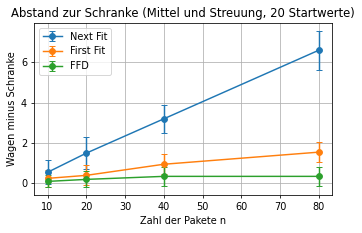

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5.5, 3.2))
ns = [10, 20, 40, 80]
for name, verfahren in [('Next Fit', next_fit), ('First Fit', first_fit), ('FFD', ffd)]:
    mittel = []
    streuung = []
    for n in ns:
        def fall(startwert):
            return zufallsfall(startwert, n, 10, 60)
        # dein Code: werte = experiment(...) mit den Startwerten 1 bis 20; Mittel und Streuung anhängen
        mittel.append(0)
        streuung.append(0)
    plt.errorbar(ns, mittel, yerr=streuung, capsize=3, marker='o', label=name)
plt.xlabel('Zahl der Pakete n')
plt.ylabel('Wagen minus Schranke')
plt.title('Abstand zur Schranke (Mittel und Streuung, 20 Startwerte)')
plt.legend()
plt.grid(True)
plt.show()

<details>
<summary>Tipp anzeigen</summary>

`werte = experiment(abstand, verfahren, fall, range(1, 21))`, danach `mittel.append(statistics.mean(werte))` und `streuung.append(statistics.pstdev(werte))`.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt

plt.figure(figsize=(5.5, 3.2))
ns = [10, 20, 40, 80]
for name, verfahren in [('Next Fit', next_fit), ('First Fit', first_fit), ('FFD', ffd)]:
    mittel = []
    streuung = []
    for n in ns:
        def fall(startwert):
            return zufallsfall(startwert, n, 10, 60)
        werte = experiment(abstand, verfahren, fall, range(1, 21))
        mittel.append(statistics.mean(werte))
        streuung.append(statistics.pstdev(werte))
    plt.errorbar(ns, mittel, yerr=streuung, capsize=3, marker='o', label=name)
plt.xlabel('Zahl der Pakete n')
plt.ylabel('Wagen minus Schranke')
plt.title('Abstand zur Schranke (Mittel und Streuung, 20 Startwerte)')
plt.legend()
plt.grid(True)
plt.show()
```

Next Fit entfernt sich mit wachsendem `n` immer weiter von der Schranke (von 0,55 bei `n = 10` auf 6,6 bei `n = 80`, der Abstand wächst etwa **linear** mit `n`), First Fit wächst langsam (0,25 auf 1,55), FFD bleibt fast flach (0,1 auf 0,35). Bei `n = 10` überlappen sich die Streuungsstriche von First Fit und FFD, bei `n = 80` nicht mehr: Der Unterschied **wächst mit `n`**. Solche Trends siehst du in einer Tabelle nicht so schnell.

</details>

#### Aufgabe 5.2

Ein **Streudiagramm** zeigt jeden Fall als Punkt: x ist der Messwert von Verfahren A, y der von Verfahren B. Punkte **unterhalb** der gestrichelten Diagonalen sind Fälle, in denen B weniger Wagen braucht. Weil die Messwerte ganze Zahlen sind, liegen viele Fälle auf demselben Punkt. Deshalb **zählt** der Code erst, wie oft jeder Punkt vorkommt, und macht den Punkt entsprechend **größer**. Führe die Zelle aus und lies das Bild: Wo liegen die meisten Fälle? Gibt es einen Punkt oberhalb der Linie?

**Erwartete Ausgabe:**
```
13 verschiedene Punkte; 98 Fälle unterhalb der Linie (First Fit besser)
```

**So etwa sollte dein Bild aussehen:**

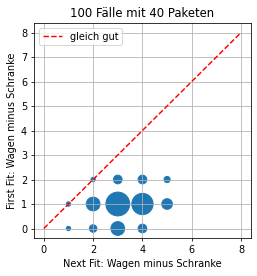

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 4))
# dein Code: Streudiagramm Next Fit gegen First Fit (Code unten in der Lösung)
plt.show()

<details>
<summary>Tipp anzeigen</summary>

Du musst nur die Lösung ausführen und das Bild lesen. Das Wörterbuch `zaehler` zählt, wie oft jedes Wertepaar vorkommt: `zaehler.get(punkt, 0) + 1` ist 1 beim ersten Mal und sonst der alte Wert plus 1.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt

zaehler = {}                                          # (Wert A, Wert B) -> wie oft
for startwert in range(1, 101):
    pakete = zufallsfall(startwert, 40, 10, 60)
    punkt = (abstand(next_fit, pakete), abstand(first_fit, pakete))
    zaehler[punkt] = zaehler.get(punkt, 0) + 1
xs = []
ys = []
groessen = []
for (a, b), wie_oft in zaehler.items():
    xs.append(a)
    ys.append(b)
    groessen.append(20 * wie_oft)                     # je mehr Fälle, desto größer der Punkt
plt.figure(figsize=(4, 4))
plt.scatter(xs, ys, s=groessen)
plt.plot([0, 8], [0, 8], 'r--', label='gleich gut')
plt.xlabel('Next Fit: Wagen minus Schranke')
plt.ylabel('First Fit: Wagen minus Schranke')
plt.title('100 Fälle mit 40 Paketen')
plt.legend()
plt.grid(True)
plt.show()
print(len(zaehler), 'verschiedene Punkte;', sum([w for (a, b), w in zaehler.items() if b < a]), 'Fälle unterhalb der Linie (First Fit besser)')
```

Alle Punkte liegen **auf oder unterhalb** der Diagonalen: First Fit ist nie schlechter als Next Fit, meist deutlich besser. (Das gilt nicht allgemein, nur für diese Fälle.) Mit dem Streudiagramm siehst du Unterschiede **pro Fall**, die ein Mittelwert versteckt.

</details>

#### Aufgabe 5.3

Ein **Boxplot** zeigt die ganze Verteilung der Messwerte eines Verfahrens: der **Strich** ist der Median, der **Kasten** enthält die mittlere Hälfte der Werte, die **Striche daran** reichen bis zu den entferntesten normalen Werten, **Punkte** sind Ausreißer. Zeichne ihn für die drei Verfahren bei 100 Fällen mit 40 Paketen.

**Erwartete Ausgabe:**
```
[1, 0, 0] [5, 2, 1]
```

**So etwa sollte dein Bild aussehen:**

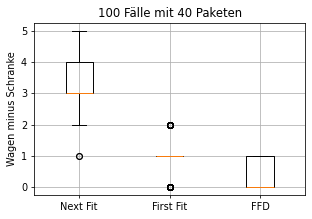

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 3.2))
# dein Code: Liste von drei Listen bilden und plt.boxplot(...) aufrufen
plt.show()

<details>
<summary>Tipp anzeigen</summary>

`listen` ist eine Liste aus **drei Listen** von Messwerten, in der Reihenfolge der Namen. Jede Liste liefert `experiment(abstand, verfahren, fall40, range(1, 101))`.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt

namen = ['Next Fit', 'First Fit', 'FFD']
listen = []
for verfahren in [next_fit, first_fit, ffd]:
    listen.append(experiment(abstand, verfahren, fall40, range(1, 101)))
plt.figure(figsize=(5, 3.2))
plt.boxplot(listen)
plt.xticks([1, 2, 3], namen)                            # die Namen unter die drei Kästen
plt.ylabel('Wagen minus Schranke')
plt.title('100 Fälle mit 40 Paketen')
plt.grid(True)
plt.show()
print([min(l) for l in listen], [max(l) for l in listen])
```

Der Boxplot zeigt das, was ein Mittelwert nicht zeigt: die ganze **Spanne**. Next Fit liegt bei diesen 100 Fällen zwischen 1 und 5 Wagen über der Schranke, First Fit zwischen 0 und 2, FFD zwischen 0 und 1: Die Kästen von Next Fit (Wagen 3 bis 4 über der Schranke) und den beiden anderen überlappen sich nicht. Der Kasten von First Fit ist **flach**: Die mittlere Hälfte der Fälle liegt genau bei 1, die Werte 0 und 2 erscheinen als Punkte. Mit Ausreißern geht ein Boxplot **ehrlich** um: Sie sind sichtbare Punkte statt versteckter Zahlen.

</details>

#### Frage 5.4

Welche Art von Diagramm passt am besten zu welcher Frage?

1. „Wie wächst der Abstand mit der Zahl der Pakete?“
2. „Ist Verfahren B in **jedem** Fall mindestens so gut wie Verfahren A?“
3. „Wie breit streuen die Ergebnisse eines Verfahrens, und gibt es Ausreißer?“

✏️ *Deine Antwort (Doppelklick zum Bearbeiten):*

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

1. **Linie mit Streuung** (`errorbar`): x ist `n`, y das Mittel, ein Strich pro Wert zeigt die Streuung.
2. **Streudiagramm** mit der Diagonalen: Jeder Fall ist ein Punkt, und man sieht sofort, ob einer auf der falschen Seite liegt.
3. **Boxplot** (oder ein Histogramm): zeigt Median, mittlere Hälfte und Ausreißer.

</details>

## 6. Wachstum messen

Willst du wissen, ob dein Verfahren auch für **große** Eingaben reicht, misst du **Zähler** bei `n`, `2n`, `4n`, `8n` ... und schaust, **um welchen Faktor** sie wachsen. Die O-Notation (aus [Notebook 01 von learn_bwinf1](https://ktheu.github.io/bwinfN/notebooks/index.html?path=learn_bwinf1/01_durchprobieren.ipynb)) sagt dir, was zu erwarten ist:

| Wächst die Zahl der Schritte um den Faktor ... wenn `n` sich verdoppelt | dann etwa |
|---|---|
| 2 | O(n) |
| etwas mehr als 2 (2,1; 2,2) | O(n log n) |
| 4 | O(n²) |
| 8 | O(n³) |

Next Fit schaut jedes Paket genau einmal an: O(n). First Fit vergleicht jedes Paket mit **allen bisherigen Wagen**, deren Zahl mit `n` wächst: O(n²). Mal sehen, ob die Zähler das bestätigen.

#### Aufgabe 6.1

Miss die **Vergleiche** (Messgröße `vergleichszahl`) der drei Verfahren bei `n` = 100, 200, 400 und 800 Paketen (Startwert 1, Gewichte 10 bis 60) und berechne bei jeder Verdopplung den **Faktor** (neuer Zähler durch alten). Die Ausgabe ist fast fertig: Du musst nur den Faktor berechnen.

**Erwartete Ausgabe:**
```
    n   NextFit  Faktor   FirstFit  Faktor        FFD  Faktor
  100       100      -      1794      -      2225      -
  200       200   2.00      7411   4.13      8761   3.94
  400       400   2.00     29248   3.95     34117   3.89
  800       800   2.00    114404   3.91    136507   4.00
```

In [ ]:
print('    n   NextFit  Faktor   FirstFit  Faktor        FFD  Faktor')
vorher = [None, None, None]
for n in [100, 200, 400, 800]:
    pakete = zufallsfall(1, n, 10, 60)
    zeile_text = f'{n:5}'
    for i, verfahren in enumerate([next_fit, first_fit, ffd]):
        z = vergleichszahl(verfahren, pakete)
        if vorher[i] is None:
            faktor = '     -'
        else:
            faktor = '     ?'                               # dein Code: z durch vorher[i], auf zwei Stellen
        zeile_text = zeile_text + f'{z:10} {faktor}'
        vorher[i] = z
    print(zeile_text)

<details>
<summary>Tipp anzeigen</summary>

`faktor = f'{z / vorher[i]:6.2f}'` rechnet und formatiert in einem Schritt (sechs Zeichen breit, zwei Nachkommastellen).

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
print('    n   NextFit  Faktor   FirstFit  Faktor        FFD  Faktor')
vorher = [None, None, None]
for n in [100, 200, 400, 800]:
    pakete = zufallsfall(1, n, 10, 60)
    zeile_text = f'{n:5}'
    for i, verfahren in enumerate([next_fit, first_fit, ffd]):
        z = vergleichszahl(verfahren, pakete)
        if vorher[i] is None:
            faktor = '     -'
        else:
            faktor = f'{z / vorher[i]:6.2f}'
        zeile_text = zeile_text + f'{z:10} {faktor}'
        vorher[i] = z
    print(zeile_text)
```

Next Fit: Faktor **2,00** bei jeder Verdopplung (O(n)). First Fit und FFD: Faktor **etwa 4** (O(n²)). Der Faktor ist nicht genau 4 (er schwankt zwischen 3,9 und 4,1), weil es nur **ein** Fall je `n` ist: Wie viele Wagen offen bleiben, hängt vom Zufall der Gewichte ab.

</details>

#### Aufgabe 6.2

Bei der **doppelt-logarithmischen** Darstellung (`plt.loglog`) tragen beide Achsen Zehnerpotenzen ab. Dann wird jede **Potenz** `n^k` zu einer **Geraden mit Steigung k**. Du siehst also die O-Notation direkt am Diagramm: Next Fit (O(n)) liegt auf einer Geraden mit Steigung 1, First Fit (O(n²)) auf einer doppelt so steilen. Führe die Zelle aus und vergleiche die Steigung beider Linien.

**So etwa sollte dein Bild aussehen:**

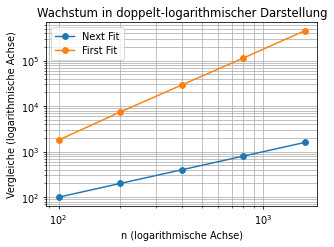

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 3.4))
# Lösung ausführen: plt.loglog statt plt.plot
plt.show()

<details>
<summary>Tipp anzeigen</summary>

Du musst nur die Lösung ausführen. Messwerte auf einer Geraden heißen „Potenzgesetz“; die Steigung der Geraden ist der **Exponent**.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt

ns = [100, 200, 400, 800, 1600]
plt.figure(figsize=(5, 3.4))
for name, verfahren in [('Next Fit', next_fit), ('First Fit', first_fit)]:
    zaehler = []
    for n in ns:
        zaehler.append(vergleichszahl(verfahren, zufallsfall(1, n, 10, 60)))
    plt.loglog(ns, zaehler, 'o-', label=name)
plt.xlabel('n (logarithmische Achse)')
plt.ylabel('Vergleiche (logarithmische Achse)')
plt.title('Wachstum in doppelt-logarithmischer Darstellung')
plt.legend()
plt.grid(True, which='both')
plt.show()
```

Die Linie von First Fit ist etwa doppelt so steil wie die von Next Fit (Steigung 2 gegen 1). Das ist die Aussage der O-Notation, **gemessen** und nicht nur behauptet. Das ist ein **starker Beleg** in einer Dokumentation: Er enthält weder Sekunden noch eine Behauptung.

</details>

#### Frage 6.3

1. First Fit braucht bei 800 Paketen etwa 15-mal so viele Vergleiche wie bei 200. Wie viele Vergleiche erwartest du bei 8000 Paketen im Vergleich zu 800, und was heißt das für eine Aufgabe mit 20 000 Paketen?
2. FFD sortiert zuerst. Das Sortieren wird in `vergleichszahl` nicht mitgezählt. Warum ändert das trotzdem nichts an der Aussage O(n²)?
3. Wie kann man First Fit **schneller** machen (nicht verlangt, nur eine Idee)?

✏️ *Deine Antwort (Doppelklick zum Bearbeiten):*

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

1. Zehnmal so viele Pakete heißt bei O(n²) hundertmal so viele Vergleiche. Bei 20 000 Paketen sind es das 625-fache von 800 Paketen. Das heißt: Ist die Aufgabe so groß, braucht man ein schnelleres Verfahren, oder man **misst vorher**, wie lange es dauert, statt zu hoffen.
2. Das Sortieren braucht nur O(n log n) Vergleiche, das ist für große `n` **viel weniger** als n². Der n²-Teil bestimmt das Wachstum, der kleinere fällt heraus.
3. Die Wagen in einem Suchbaum (oder einer Segmentbaum-Struktur) nach freiem Platz ordnen, dann findet man den ersten passenden Wagen in O(log n) statt O(n): insgesamt O(n log n). Das geht über den Stoff dieses Notebooks hinaus, aber das Wachstum **sagt dir**, wo es sich lohnt.

</details>

## 7. Typische Fehler im Überblick

| Fehler | Folge | Gegenmittel |
|---|---|---|
| nur **ein Startwert** oder nur die offiziellen Beispiele | Zufallstreffer, der Zufall der Fälle | viele Startwerte, Zahl in der Dokumentation nennen |
| **verschiedene Fälle** für verschiedene Verfahren | ein „Unterschied“ ohne Verfahren | gleiche Fälle, paarweise vergleichen |
| **Sekunden** als Messgröße | nicht reproduzierbar | Zähler, Güte (Schranke, Optimum) |
| nur das **Mittel** angeben | Ausreißer und Streuung verschwinden | Streuung, kleinsten und größten Wert, Median |
| **Ausreißer verschweigen** | wirkt besser, als es ist | immer den **schlechtesten** Fall nennen und anschauen |
| zu **kleine Fälle** | Wachstum bleibt unsichtbar | zusätzlich große Fälle (`n`, `2n`, `4n`) |
| nur **Zufallsfälle** | Grenzfälle brechen das Programm | `grenzfaelle` und Regressionstest |
| **Ergebnis ungeprüft** | ungültige Lösungen werden mitgezählt | **Schiedsrichter** in jeder Messung |
| **Schlüsse ohne Maßstab** | „10 Wagen“ sagt nichts | Schranke, Optimum kleiner Fälle oder anderes Verfahren dazu |

Der **Schiedsrichter** war in `abstand` schon eingebaut (`assert urteil == 'ok'`): Bricht ein Verfahren die Regeln, stürzt das Experiment mit einer Meldung ab, statt eine falsche Tabelle zu liefern.

### Den schlechtesten Fall anschauen

Zum **ehrlichen** Umgang mit Ausreißern gehört: den schlechtesten Fall **suchen** und **anschauen**. Oft zeigt er, warum das Verfahren dort schlecht ist.

In [ ]:
w = experiment(abstand, next_fit, fall40, range(1, 101))
schlimmster = w.index(max(w)) + 1                             # der Startwert mit dem größten Abstand
print('Mittel', round(statistics.mean(w), 2), ', Median', statistics.median(w), ', größter Abstand', max(w), 'bei Startwert', schlimmster)
pakete = zufallsfall(schlimmster, 40, 10, 60)
fuellung, vergleiche = next_fit(pakete, K)
print('Wagen', len(fuellung), ', Schranke', schranke(pakete, K), ', Füllstände', fuellung)

Mittel 3.3 , Median 3.0 , größter Abstand 5 bei Startwert 24
Wagen 21 , Schranke 16 , Füllstände [89, 91, 62, 52, 68, 55, 77, 83, 56, 69, 77, 56, 78, 63, 98, 91, 85, 53, 84, 69, 53]


#### Frage 7.1

Next Fit hat bei den 100 Fällen mit 40 Paketen einen größten Abstand von **5** zur Schranke, der Mittelwert ist 3,3.

1. Warum wäre es unehrlich, in der Dokumentation nur das Mittel zu nennen?
2. Was sieht man an den Füllständen des schlechtesten Falls?

✏️ *Deine Antwort (Doppelklick zum Bearbeiten):*

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

1. Wer sich auf ein Verfahren verlassen will, will wissen, **wie schlecht es werden kann**. Das Mittel verschweigt, dass es Fälle gibt, in denen das Ergebnis viel schlechter als typisch ist. Dasselbe gilt für den kleinsten Wert (bester Fall).
2. Mehrere Wagen sind nur etwa **halb voll** (52, 53 und 55 kg bei einer Kapazität von 100): Next Fit schließt einen Wagen, sobald ein Paket nicht mehr passt, und kommt nie zurück, um die Lücke zu füllen. Das erklärt, **warum** der Abstand wächst, und liefert einen Satz für die Dokumentation.

</details>

## Wettbewerbs-Ecke: Gießroboter

*Angelehnt an Aufgabe 2 „Gießroboter“ der 2. Runde des 44. Bundeswettbewerbs Informatik (2025/26).*

Ein botanischer Garten will seine Bäume mit **möglichst wenigen** Gießrobotern bewässern. Jeder Roboter fährt eine **Rundroute** (Start und Ende an seiner Ladestation), und jede Route darf höchstens `lmax` lang sein. Jeder Baum muss auf einer Route liegen. Die Bäume sind Punkte `(x, y)`.

Das Lösungsnotebook [Gießroboter](https://ktheu.github.io/bwinfN/notebooks/index.html?path=bwinf2/44_Giessroboter/giessroboter_loesung.ipynb) baut die Routen gierig (Notebook 03 hat Heuristiken wie diese), verkürzt sie mit **2-opt** und löst am Ende überflüssige Routen auf. Hier geht es **nicht** um diese Verfahren, sondern um das **Experiment**: Welche Variante ist wie viel besser, und wie sicher ist das? Die Routen-Heuristik (2-opt, Einfügen mit kleinstem Umweg) ist deshalb **gegeben** und wird in einem späteren Themen-Notebook über Touren ausführlich behandelt. Du musst sie nicht verstehen, nur **benutzen**.

**Die Varianten** (jede gibt zu `baeume` und `lmax` eine Liste von Routen zurück):

| Name | Verfahren |
|---|---|
| `v_einfuegen` | Routen nur durch Einfügen mit kleinstem Umweg |
| `v_zwei_opt` | dazu 2-opt nach jedem Einfügen |
| `v_eta02` | 2-opt, dazu werden **Randbäume** bevorzugt (`eta = 0,2`, Gewicht für den Abstand zur Mitte) |
| `v_eta05` | wie `v_eta02`, aber `eta = 0,5` |

**Messgrößen:** die **Zahl der Roboter** (kleiner ist besser, geprüft mit einem Schiedsrichter `pruefe_routen`), die **untere Schranke** `schranke_roboter` (Bäume, die weiter als `lmax / 2` voneinander entfernt liegen, brauchen verschiedene Roboter) und die **Zahl der berechneten Abstände** als Zähler für die Rechenarbeit.

In [ ]:
from math import sqrt
import random

ZAEHLER = [0]                                      # zählt alle Abstandsberechnungen


def abstand_zwei(baeume, i, j):
    ZAEHLER[0] = ZAEHLER[0] + 1
    return sqrt((baeume[i][0] - baeume[j][0]) ** 2 + (baeume[i][1] - baeume[j][1]) ** 2)


def route_laenge(baeume, route):
    summe = 0.0
    for k in range(len(route)):
        summe = summe + abstand_zwei(baeume, route[k], route[(k + 1) % len(route)])
    return summe


def beste_stelle(baeume, route, c):
    """Wo kostet es am wenigsten Umweg, Baum c in die Route einzufügen?"""
    if len(route) == 1:
        return 2 * abstand_zwei(baeume, route[0], c), 1
    bester_umweg = None
    beste_position = 0
    for k in range(len(route)):
        a = route[k]
        b = route[(k + 1) % len(route)]
        umweg = abstand_zwei(baeume, a, c) + abstand_zwei(baeume, c, b) - abstand_zwei(baeume, a, b)
        if bester_umweg is None or umweg < bester_umweg:
            bester_umweg = umweg
            beste_position = k + 1
    return bester_umweg, beste_position


def zwei_opt(baeume, route):
    """Kreuzungen auflösen: ein Stück der Route umdrehen, solange es die Route kürzer macht."""
    n = len(route)
    verbessert = True
    while verbessert:
        verbessert = False
        for i in range(n - 1):
            for j in range(i + 2, n):
                if i == 0 and j == n - 1:
                    continue
                a = route[i]
                b = route[i + 1]
                c = route[j]
                e = route[(j + 1) % n]
                alt = abstand_zwei(baeume, a, b) + abstand_zwei(baeume, c, e)
                neu = abstand_zwei(baeume, a, c) + abstand_zwei(baeume, b, e)
                if neu < alt - 0.000000001:
                    route[i + 1:j + 1] = route[i + 1:j + 1][::-1]
                    verbessert = True
    return route


def baue_route(baeume, lmax, mitte, start, frei, eta, mit_zwei_opt):
    """Eine Route ab start: immer den Baum einfügen, der am wenigsten Umweg kostet (minus eta mal Abstand zur Mitte)."""
    route = [start]
    laenge = 0.0
    frei[start] = False
    kandidaten = []
    for c in range(len(baeume)):
        if frei[c] and abstand_zwei(baeume, start, c) <= lmax / 2:     # weiter weg kann nie auf derselben Route liegen
            kandidaten.append(c)
    while len(kandidaten) > 0:
        bester = None
        passende = []
        for c in kandidaten:
            umweg, position = beste_stelle(baeume, route, c)
            if laenge + umweg <= lmax - 0.000001:
                passende.append(c)
                punkte = umweg - eta * mitte[c]
                if bester is None or punkte < bester[0]:
                    bester = (punkte, c, position)
        kandidaten = passende
        if bester is None:
            break
        punkte, c, position = bester
        route.insert(position, c)
        frei[c] = False
        kandidaten.remove(c)
        if mit_zwei_opt and len(route) >= 4:
            route = zwei_opt(baeume, route)
        laenge = route_laenge(baeume, route)
    return route


def loese_garten(baeume, lmax, eta, mit_zwei_opt):
    """Bäume von außen nach innen als Start einer neuen Route, solange noch Bäume frei sind."""
    mx = sum([b[0] for b in baeume]) / len(baeume)
    my = sum([b[1] for b in baeume]) / len(baeume)
    mitte = [sqrt((b[0] - mx) ** 2 + (b[1] - my) ** 2) for b in baeume]
    paare = [(-mitte[i], i) for i in range(len(baeume))]
    paare.sort()
    frei = [True] * len(baeume)
    routen = []
    for m, start in paare:
        if frei[start]:
            routen.append(baue_route(baeume, lmax, mitte, start, frei, eta, mit_zwei_opt))
    return routen


# Die Varianten, die wir vergleichen: alle haben dieselbe Form (baeume, lmax) -> Routen
def v_einfuegen(baeume, lmax):
    return loese_garten(baeume, lmax, 0, False)       # nur Einfügen mit kleinstem Umweg


def v_zwei_opt(baeume, lmax):
    return loese_garten(baeume, lmax, 0, True)        # dazu 2-opt nach jedem Einfügen


def v_eta02(baeume, lmax):
    return loese_garten(baeume, lmax, 0.2, True)      # 2-opt, Bäume am Rand bevorzugt (eta = 0.2)


def v_eta05(baeume, lmax):
    return loese_garten(baeume, lmax, 0.5, True)      # 2-opt, Bäume am Rand stärker bevorzugt (eta = 0.5)


def pruefe_routen(baeume, lmax, routen):
    """Schiedsrichter: ist jeder Baum auf genau einer Route, und ist keine Route länger als lmax?"""
    gesehen = [0] * len(baeume)
    for route in routen:
        if route_laenge(baeume, route) > lmax:
            return 'eine Route ist zu lang'
        for baum in route:
            gesehen[baum] = gesehen[baum] + 1
    if gesehen != [1] * len(baeume):
        return 'nicht jeder Baum liegt auf genau einer Route'
    return 'ok'


def schranke_roboter(baeume, lmax):
    """Untere Schranke: Bäume, die weiter als lmax / 2 auseinander liegen, brauchen verschiedene Roboter."""
    gewaehlt = []
    for i in range(len(baeume)):
        passt = True
        for j in gewaehlt:
            if sqrt((baeume[i][0] - baeume[j][0]) ** 2 + (baeume[i][1] - baeume[j][1]) ** 2) <= lmax / 2:
                passt = False
                break
        if passt:
            gewaehlt.append(i)
    return len(gewaehlt)


def lies_garten(dateiname):
    with open(dateiname, encoding='utf-8') as f:
        zeilen = [z.split() for z in f.read().splitlines() if z.split()]
    lmax = int(zeilen[0][0])
    baeume = []
    for z in zeilen[2:]:
        baeume.append((int(z[1]), int(z[2])))
    return lmax, baeume


def zufallsgarten(startwert, n, seite):
    """n Bäume gleichmäßig verteilt auf dem Quadrat 0 bis seite."""
    zufall = random.Random(startwert)
    baeume = []
    for i in range(n):
        baeume.append((zufall.randint(0, seite), zufall.randint(0, seite)))
    return baeume

def roboter(verfahren, garten):
    """Messgröße 1: Zahl der Roboter. Ein Garten ist das Paar (baeume, lmax)."""
    baeume, lmax = garten
    routen = verfahren(baeume, lmax)
    urteil = pruefe_routen(baeume, lmax, routen)
    assert urteil == 'ok', urteil
    return len(routen)


def abstandsrechnungen(verfahren, garten):
    """Messgröße 2: Zahl der berechneten Abstände (ein Zähler statt Sekunden)."""
    baeume, lmax = garten
    ZAEHLER[0] = 0
    verfahren(baeume, lmax)
    return ZAEHLER[0]


def garten40(startwert):
    return zufallsgarten(startwert, 40, 100), 150

**1. Auf den Beispielen.** Die Beispiele der Aufgabe sind groß; hier liegen **verkleinerte Ausschnitte** (die ersten 60 oder weniger Bäume der echten Beispiele `roboter01` bis `roboter06`, mit ihrem `lmax`) in `daten/giessroboter*.txt`. Wie viele Roboter braucht jede Variante, und wie viele sagt das Lösungsnotebook für diese Fälle?

In [ ]:
dateien = ['giessroboter01.txt', 'giessroboter02.txt', 'giessroboter04_40.txt', 'giessroboter04_80.txt',
           'giessroboter05_60.txt', 'giessroboter06_60.txt']
varianten = [('einfügen', v_einfuegen), ('2-opt', v_zwei_opt), ('eta 0,2', v_eta02), ('eta 0,5', v_eta05)]
print('Datei                 Bäume  lmax  Schranke ' + ' '.join([f'{name:>9}' for name, v in varianten]))
for datei in dateien:
    lmax, baeume = lies_garten('daten/' + datei)
    zahlen = [roboter(v, (baeume, lmax)) for name, v in varianten]
    print(f'{datei:21} {len(baeume):5} {lmax:5} {schranke_roboter(baeume, lmax):8} ' + ' '.join([f'{z:9}' for z in zahlen]))

Datei                 Bäume  lmax  Schranke  einfügen     2-opt   eta 0,2   eta 0,5
giessroboter01.txt       13   175        2         3         3         3         3
giessroboter02.txt       18   175        6         8         8         9         8
giessroboter04_40.txt    40   100        5         9         9         9         9
giessroboter04_80.txt    80   100       10        16        16        16        16
giessroboter05_60.txt    60  1400        2         2         2         2         2
giessroboter06_60.txt    60   700        2         2         2         2         2


Die Zahlen **stimmen mit dem Lösungsnotebook überein**: Dessen gieriger Aufbau (beste der Werte `eta = 0,2` und `eta = 0,5`, vor dem Auflösen) liefert für diese Ausschnitte 3, 8, 9, 16, 2 und 2 Roboter, das ist hier jeweils der **kleinere** Wert der beiden letzten Spalten. Das Auflösen von Routen, das das Lösungsnotebook danach noch versucht, spart bei diesen kleinen Ausschnitten keinen weiteren Roboter.

Beobachtungen:

- Die vier Varianten liefern auf diesen sechs Fällen **fast immer dasselbe**. Nur bei `giessroboter02.txt` ist `eta = 0,2` schlechter als die anderen.
- Die Schranke ist bei den **letzten beiden** Dateien (2 Roboter) erreicht: dort sind die Lösungen **nachweislich optimal**. Bei den anderen liegt sie 1 bis 6 darunter. Eine schwache Schranke bedeutet **nicht**, dass das Verfahren schlecht ist.
- **Folge:** Mit den Beispielen der Aufgabe allein kann man die Varianten **nicht unterscheiden**. Dazu brauchst du **viele eigene Gärten**: Zufallsgärten mit Startwert.

#### Aufgabe G.1

**2. Der Vergleich auf Zufallsgärten.** `garten40(startwert)` erzeugt einen Garten mit 40 gleichmäßig verteilten Bäumen auf dem Quadrat `0` bis `100` und `lmax = 150`. `zeile` gibt Mittel, Median, Streuung, kleinsten und größten Wert aus (kennst du aus Abschnitt 3). Schreibe die Schleife, die für die **vier Varianten** je eine Zeile für die Startwerte 1 bis 15 ausgibt (`experiment(roboter, verfahren, garten40, range(1, 16))`), und füge eine Zeile für die **Schranke** hinzu.

**Erwartete Ausgabe:**
```
einfügen               Mittel  4.93  Median  5.0  Streuung 0.57  kleinster  4  größter  6
2-opt                  Mittel  4.93  Median  5.0  Streuung 0.57  kleinster  4  größter  6
eta 0,2                Mittel  4.73  Median  5.0  Streuung 0.44  kleinster  4  größter  5
eta 0,5                Mittel  4.67  Median  5.0  Streuung 0.47  kleinster  4  größter  5
untere Schranke        Mittel  2.07  Median  2.0  Streuung 0.68  kleinster  1  größter  3
```

In [ ]:
for name, verfahren in [('einfügen', v_einfuegen), ('2-opt', v_zwei_opt), ('eta 0,2', v_eta02), ('eta 0,5', v_eta05)]:
    pass                                                    # dein Code: eine Zeile je Variante
schranken = []
# dein Code: die Schranken der 15 Gärten bestimmen (schranke_roboter(baeume, lmax))
zeile('untere Schranke', schranken if schranken else [0])

<details>
<summary>Tipp anzeigen</summary>

`zeile(name, experiment(roboter, verfahren, garten40, range(1, 16)))`. Für die Schranke: `baeume, lmax = garten40(s)` in einer Schleife über `s`.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
for name, verfahren in [('einfügen', v_einfuegen), ('2-opt', v_zwei_opt), ('eta 0,2', v_eta02), ('eta 0,5', v_eta05)]:
    zeile(name, experiment(roboter, verfahren, garten40, range(1, 16)))
schranken = [schranke_roboter(garten40(s)[0], garten40(s)[1]) for s in range(1, 16)]
zeile('untere Schranke', schranken)
```

Die vier Mittelwerte liegen zwischen 4,67 und 4,93, ihr Abstand (0,27) ist **kleiner als jede einzelne Streuung** (0,44 bis 0,57), und die Schranke (im Mittel 2,07) ist weit weg. `einfügen` und `2-opt` haben sogar **dieselben** Zahlen. Mit den Mittelwerten allein kann man **kaum etwas** entscheiden. Das ist die Lage, in der man die Fälle **paarweise** vergleichen muss.

</details>

**3. Paarweise.** Die Funktion `unterschiede` aus Abschnitt 4 ist wieder da (zur Sicherheit neu definiert). Sie vergleicht **für jeden Garten** zwei Varianten. „Besser“ heißt hier: **weniger Roboter** als `v_einfuegen`.

In [ ]:
def unterschiede(messgroesse, verfahren_a, verfahren_b, erzeuger, startwerte):
    """Für jeden Fall: Messwert von A minus Messwert von B."""
    d = []
    for startwert in startwerte:
        fall = erzeuger(startwert)                     # EIN Fall, beide Verfahren
        d.append(messgroesse(verfahren_a, fall) - messgroesse(verfahren_b, fall))
    return d

for name, verfahren in [('2-opt', v_zwei_opt), ('eta 0,2', v_eta02), ('eta 0,5', v_eta05)]:
    d = unterschiede(roboter, v_einfuegen, verfahren, garten40, range(1, 16))
    print(f'einfügen minus {name:8}: besser in {len([x for x in d if x > 0]):2}, gleich in {d.count(0):2}, schlechter in {len([x for x in d if x < 0]):2} von 15,'
          f' Mittel der Differenz {statistics.mean(d):5.2f}, Streuung {statistics.pstdev(d):4.2f}')

einfügen minus 2-opt   : besser in  0, gleich in 15, schlechter in  0 von 15, Mittel der Differenz  0.00, Streuung 0.00
einfügen minus eta 0,2 : besser in  3, gleich in 12, schlechter in  0 von 15, Mittel der Differenz  0.20, Streuung 0.40
einfügen minus eta 0,5 : besser in  4, gleich in 11, schlechter in  0 von 15, Mittel der Differenz  0.27, Streuung 0.44


Die Zeilen lesen sich so: „besser“ heißt, die Variante braucht in diesem Garten **weniger** Roboter als `v_einfuegen`.

- **2-opt** ändert die Zahl der Roboter in **keinem** der 15 Gärten (15 mal gleich): Die kürzeren Routen verschaffen hier keinem weiteren Baum Platz.
- **`eta = 0,2`** ist in 3 Gärten besser, in 0 schlechter, im Mittel 0,20 Roboter weniger.
- **`eta = 0,5`** ist in 4 Gärten besser, in 0 schlechter, im Mittel 0,27 Roboter weniger.

Das ist ein **kleiner**, aber **einseitiger** Unterschied: Die Randbäume zuerst zu nehmen hilft manchmal und schadet in diesen 15 Gärten nie. Mit 15 Gärten ist das ein **Hinweis**, noch kein Beweis. Mit mehr Startwerten (zum Beispiel 100) würdest du es sicherer wissen.

**4. Was kostet das?** 2-opt macht die Route kürzer, **kostet aber Rechenarbeit**. Wir zählen die Abstandsberechnungen statt Sekunden (Messgröße `abstandsrechnungen`):

In [ ]:
for name, verfahren in [('einfügen', v_einfuegen), ('2-opt', v_zwei_opt), ('eta 0,5', v_eta05)]:
    z = experiment(abstandsrechnungen, verfahren, garten40, range(1, 16))
    print(f'{name:10} Abstandsberechnungen im Mittel {statistics.mean(z):8.0f}')

einfügen   Abstandsberechnungen im Mittel     4120
2-opt      Abstandsberechnungen im Mittel     6205
eta 0,5    Abstandsberechnungen im Mittel     6453


2-opt kostet etwa das **1,5-Fache** an Abstandsberechnungen gegenüber dem reinen Einfügen und bringt in diesen Gärten keinen Roboter. Der Parameter `eta` kostet gegenüber `v_zwei_opt` nur etwa **4 %** mehr und bringt hier etwas. Ein solcher **Aufwand-Nutzen-Vergleich** gehört in die Dokumentation. (Dass 2-opt hier nichts nützt, liegt daran, dass die Routen kurz sind: wenige Bäume, kaum Kreuzungen. Bei Routen mit vielen Bäumen sieht das anders aus. Das ist ein Grund für ein **zweites Experiment** mit einem anderen `lmax`, wie gleich.)

#### Aufgabe G.2

**5. Die Variable `lmax`.** Wie hängt die Zahl der Roboter von der erlaubten Routenlänge ab, und wird der Vorsprung von `eta = 0,5` größer oder kleiner? Zeichne **Mittel und Streuung** für `lmax` = 60, 100, 150 und 250 (40 Bäume, 12 Gärten) für drei Varianten. Das Gerüst zeichnet schon, du berechnest die Werte.

**So etwa sollte dein Bild aussehen:**

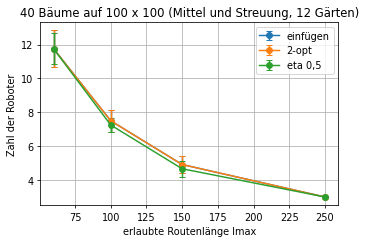

In [ ]:
import matplotlib.pyplot as plt

lmaxe = [60, 100, 150, 250]
plt.figure(figsize=(5.5, 3.4))
for name, verfahren in [('einfügen', v_einfuegen), ('2-opt', v_zwei_opt), ('eta 0,5', v_eta05)]:
    mittel = []
    streuung = []
    for lm in lmaxe:
        def garten(startwert):
            return zufallsgarten(startwert, 40, 100), lm
        # dein Code: werte = experiment(...) mit den Startwerten 1 bis 12; Mittel und Streuung anhängen
        mittel.append(0)
        streuung.append(0)
    plt.errorbar(lmaxe, mittel, yerr=streuung, capsize=3, marker='o', label=name)
plt.xlabel('erlaubte Routenlänge lmax')
plt.ylabel('Zahl der Roboter')
plt.title('40 Bäume auf 100 x 100 (Mittel und Streuung, 12 Gärten)')
plt.legend()
plt.grid(True)
plt.show()

<details>
<summary>Tipp anzeigen</summary>

Dieselbe Form wie Aufgabe 5.1: `werte = experiment(roboter, verfahren, garten, range(1, 13))`, dann Mittel und Streuung anhängen. `garten` ist eine Funktion mit dem **äußeren** `lm`, deshalb muss sie **in** der Schleife über `lm` stehen.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt

lmaxe = [60, 100, 150, 250]
plt.figure(figsize=(5.5, 3.4))
for name, verfahren in [('einfügen', v_einfuegen), ('2-opt', v_zwei_opt), ('eta 0,5', v_eta05)]:
    mittel = []
    streuung = []
    for lm in lmaxe:
        def garten(startwert):
            return zufallsgarten(startwert, 40, 100), lm
        werte = experiment(roboter, verfahren, garten, range(1, 13))
        mittel.append(statistics.mean(werte))
        streuung.append(statistics.pstdev(werte))
    plt.errorbar(lmaxe, mittel, yerr=streuung, capsize=3, marker='o', label=name)
plt.xlabel('erlaubte Routenlänge lmax')
plt.ylabel('Zahl der Roboter')
plt.title('40 Bäume auf 100 x 100 (Mittel und Streuung, 12 Gärten)')
plt.legend()
plt.grid(True)
plt.show()
```

Je größer `lmax`, desto weniger Roboter (von etwa 12 bei `lmax = 60` auf 3 bei `lmax = 250`). Die Linien von `einfügen` und `2-opt` liegen **genau übereinander**, auch bei langen Routen bringt 2-opt hier **keinen** Roboter. `eta = 0,5` liegt bei `lmax = 100` und `150` etwas darunter (um 0,25), bei 60 und 250 gleich. Die Streuungsstriche überlappen sich dabei **ganz**: Dieser Vorsprung ist so klein, dass man ihn nur mit dem paarweisen Vergleich (und mehr Gärten) absichern kann.

</details>

#### Frage G.3

Was darfst du aus dem Experiment auf Zufallsgärten **schließen**, und was **nicht**? Wähle für jede Aussage „ja“ oder „nein“ und begründe kurz.

1. „2-opt verkürzt die Routen, also braucht man weniger Roboter.“
2. „`eta = 0,5` braucht im Mittel weniger Roboter als reines Einfügen, ist aber nicht in jedem Garten besser.“
3. „`eta = 0,5` ist deutlich besser als `eta = 0,2`.“
4. „`eta = 0,5` ist auch bei den echten, größeren Beispielen der Aufgabe das beste.“
5. „Die Lösungen sind höchstens um den Faktor 3 vom Optimum entfernt.“

✏️ *Deine Antwort (Doppelklick zum Bearbeiten):*

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

1. **Nein.** 2-opt macht die **Routen** kürzer, und das kostet 1,5 mal so viel Rechenarbeit, ändert aber in keinem der 15 Gärten die Zahl der Roboter. Eine kürzere Route hilft nur dann, wenn dadurch ein weiterer Baum hineinpasst.
2. **Ja**, das zeigen die paarweisen Differenzen auf 15 Zufallsgärten: 4 besser, 11 gleich, 0 schlechter, Mittel 0,27. Mit mehr Gärten würdest du es genauer wissen.
3. **Nein, nicht belegt.** Die Mittel (4,67 gegen 4,73) unterscheiden sich um 0,06, die Streuung beträgt etwa 0,45. Und die beiden Varianten haben wir nicht **paarweise** gegeneinander gemessen. Das wäre mit `unterschiede(roboter, v_eta02, v_eta05, ...)` schnell nachgeholt.
4. **Nicht belegt.** Das Experiment betraf **gleichmäßig verteilte** Gärten mit `lmax = 150` auf 100 mal 100. Die echten Beispiele haben andere Dichten und `lmax`-Werte (siehe die sechs Ausschnitte: dort sind alle Varianten fast gleich). Man müsste es **auch dort** messen, möglichst an mehr Fällen, etwa mit **Bäumen in Gruppen** statt gleichmäßig.
5. **Nein.** Die Schranke liefert nur eine **untere** Grenze (hier im Mittel 2,07 gegen etwa 4,67 Roboter), sie ist **keine Garantie** für die Güte. Ein Faktor lässt sich daraus nur ablesen, wenn die Schranke **scharf** ist, und das war sie nur bei 2 von 6 Beispielen.

</details>

**Grenzfälle** für diese Aufgabe (baue sie wie in Abschnitt 2): ein Garten mit **einem** Baum (eine Route der Länge 0), ein Garten mit **allen Bäumen am selben Ort**, Bäume **auf einer Geraden**, ein `lmax`, bei dem jeder Baum **allein** eine Route braucht (Schranke und Ergebnis sind dann gleich `n`), und ein `lmax`, das **alles** auf eine Route lässt. Der Schiedsrichter `pruefe_routen` fängt dabei Fehler wie „Baum fehlt“ oder „Route zu lang“.

## 8. Die Ergebnisse dokumentieren

Zahlen aus einem Experiment gehören in die Einsendung, aber **so**, dass jemand sie prüfen kann. Eine gute Dokumentation eines Experiments enthält:

1. **Frage und Aufbau:** „Wir vergleichen vier Varianten des gierigen Verfahrens. Jeder Garten hat 40 Bäume, gleichmäßig verteilt auf 100 × 100, `lmax = 150`. Startwerte 1 bis 15, für alle Varianten dieselben Gärten.“
2. **Messgröße und Maßstab:** „Zahl der Roboter (kleiner ist besser), dazu eine untere Schranke.“
3. **Ergebnis als Tabelle oder Diagramm:** Mittel, Streuung, kleinster und größter Wert. Beschriftete Achsen.
4. **Paarweise Vergleiche**, wenn die Mittelwerte dicht beieinander liegen.
5. **Ehrliche Deutung:** was die Daten zeigen, was nicht (etwa: „gilt nur für gleichmäßig verteilte Bäume“), und wo die Verfahren schlecht sind (Ausreißer).
6. **Reproduzierbarkeit:** Startwerte, Parameter und Programm **angeben**, damit man die Tabelle nachrechnen kann.

Wie du solche Experimente in die ganze Dokumentation der 2. Runde einbaust und **Erweiterungen begründest**, steht im nächsten Notebook.

**MiniZinc:** Hier nicht vorgesehen. Bei diesem Notebook geht es um das **Experimentieren** mit Heuristiken auf eigenen Fällen, und MiniZinc (siehe Notebook 01 und 03) liefert das **exakte Optimum** nur bei kleinen Fällen: ein Maßstab, den die Schranke und der Vergleich der Verfahren untereinander hier ersetzen. Bei den Gärten mit Rundrouten wird ein Modell schon bei wenigen Dutzend Bäumen zu groß für eine Zelle im Browser, und die Pakete im neutralen Beispiel sind mit der Schranke gut eingeordnet.

## Das hast du gelernt

```python
def experiment(messgroesse, verfahren, erzeuger, startwerte):
    werte = []
    for startwert in startwerte:
        werte.append(messgroesse(verfahren, erzeuger(startwert)))   # gleicher Fall (Startwert) für jedes Verfahren
    return werte


def unterschiede(messgroesse, verfahren_a, verfahren_b, erzeuger, startwerte):
    d = []
    for startwert in startwerte:
        fall = erzeuger(startwert)                                  # ein Fall, beide Verfahren
        d.append(messgroesse(verfahren_a, fall) - messgroesse(verfahren_b, fall))
    return d
```

- **Ein Experiment hat eine Frage, eine Variable, feste Größen, eine Messgröße und viele Wiederholungen.** Einzelne Beispiele reichen nicht.
- **Testfälle:** Zufallsfälle mit `random.Random(startwert)` (reproduzierbar), **Grenzfälle** gezielt gebaut und bei jeder Änderung wieder ausgeführt, **große** Fälle für das Wachstum.
- **Messen ohne Sekunden:** Zähler (Schritte, Vergleiche) und **Güte** (Abstand zu Schranke oder Optimum). Ein **Schiedsrichter** prüft jede Lösung.
- **Zusammenfassen:** Mittel, Median, **Streuung**, kleinster und größter Wert. Den **schlechtesten Fall** nicht verschweigen, sondern ansehen.
- **Fair vergleichen:** gleiche Fälle, gleiches Budget, **Differenzen pro Fall**. Ein Unterschied zählt, wenn er größer als die Schwankung ist. Genug Startwerte, bis die Tabelle nicht mehr wackelt (der Fehler des Mittels sinkt wie `Streuung / Wurzel(Anzahl)`).
- **Diagramme:** `plt.errorbar` (Linie mit Streuung), `plt.scatter` (Fall gegen Fall mit Diagonale), `plt.boxplot` (Verteilung), `plt.loglog` (Potenzgesetze als Geraden). Immer beschriften.
- **Wachstum:** Zähler bei `n`, `2n`, `4n`: Faktor 2 heißt O(n), Faktor 4 heißt O(n²).
- **Ehrlich deuten:** Ein Ergebnis gilt für die **getesteten Fälle** (hier: gleichmäßig verteilte Gärten), eine schwache Schranke ist keine Garantie.

### Aufgaben der 2. Runde dazu

Bearbeite eine Aufgabe zuerst selbst und sieh dir das Lösungsnotebook erst danach an.

- [Gießroboter](https://ktheu.github.io/bwinfN/notebooks/index.html?path=bwinf2/44_Giessroboter/giessroboter_loesung.ipynb) (44. BwInf): Varianten des Verfahrens, Vergleich mit den Zahlen der Lösungshinweise
- [Stilvolle Päckchen](https://ktheu.github.io/bwinfN/notebooks/index.html?path=bwinf2/42_StilvollePaeckchen/paeckchen_loesung.ipynb) (42.): lokale Suche, Parameter und Vergleich mit dem exakten Ergebnis
- [Flohmarkt in Langdorf](https://ktheu.github.io/bwinfN/notebooks/index.html?path=bwinf2/39_FlohmarktInLangdorf/flohmarkt_loesung.ipynb) (39.): Regeln im Vergleich, Güte gegen Schranke

Mehr Aufgaben stehen in der Werkzeugübersicht der 2. Runde (Abschnitt 10 „Die Einsendung der 2. Runde“, dort auch der Verweis auf dieses Notebook). Das nächste Kern-Notebook ist **17 „Dokumentation der 2. Runde“**: Wie du Experimente wie diese **ehrlich** darstellst und **Erweiterungen begründest**. Das Notebook 05 „Touren“ (Rundreisen, 2-opt) kommt später.